# part b supermarket sales exploratory data analysis

this notebook follows understand, inspect, clean, explore, interpret.
all text is simple lowercase with a few typos.
diagnostic cells are kept in so you can prove every check.
run cells from top to bottom.

In [1]:
# import tools for tables math and plots
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# simple plot style
plt.style.use("ggplot")

## b1 dataset understandig

### load and first look

In [2]:
# read the supermarket csv
supermarket = pd.read_csv("supermarket_Sales.csv")

# print shape and first rows
print("shape:", supermarket.shape)
display(supermarket.head(5))

# print column data types
print("\ncolumn dtypes:")
print(supermarket.dtypes)

shape: (1000, 17)


,Invoice ID,Branch,City,Customer type,Gender,Product line,Unit price,Quantity,Tax 5%,Total,Date,Time,Payment,Cost of goods sold,Gross margin percentage,Gross income,Customer stratification rating
0,750-67-8428,A,Yangon,Member,Female,Health and beauty,74.69,7,26.1415,548.9715,1/5/2019,13:08,Ewallet,522.83,4.761905,26.1415,9.1
1,226-31-3081,C,Naypyitaw,Normal,Female,Electronic accessories,15.28,5,3.8200,80.2200,3/8/2019,10:29,Cash,76.40,4.761905,3.8200,9.6
2,631-41-3108,A,Yangon,Normal,Male,Home and lifestyle,46.33,7,16.2155,340.5255,3/3/2019,13:23,Credit card,324.31,4.761905,16.2155,7.4
3,123-19-1176,A,Yangon,Member,Male,Health and beauty,58.22,8,23.2880,489.0480,1/27/2019,20:33,Ewallet,465.76,4.761905,23.2880,8.4
4,373-73-7910,A,Yangon,Normal,Male,Sports and travel,86.31,7,30.2085,634.3785,2/8/2019,10:37,Ewallet,604.17,4.761905,30.2085,5.3



column dtypes:
Invoice ID                            str
Branch                                str
City                                  str
Customer type                         str
Gender                                str
Product line                          str
Unit price                        float64
Quantity                            int64
Tax 5%                            float64
Total                             float64
Date                                  str
Time                                  str
Payment                               str
Cost of goods sold                float64
Gross margin percentage           float64
Gross income                      float64
Customer stratification rating    float64
dtype: object


one row is one receipt from one customer at one branch on one day.

### variable role table

| column | type | role note |
|---|---|---|
| Invoice ID | identifier | unique receipt id |
| Branch | categorical | shop branch a, b, c |
| City | categorical | city of branch |
| Customer type | categorical | member or normal |
| Gender | categorical | male or female |
| Product line | categorical | product group of basket |
| Unit price | numerical | price of one item |
| Quantity | numerical | how many items bought |
| Tax 5% | numerical | tax on the receipt |
| Total | numerical | bill paid by customer |
| Date | date | day of purchase |
| Time | time | time of purchase |
| Payment | categorical | how customer paid |
| Cost of goods sold | numerical | shop cost of the items |
| Gross margin percentage | numerical | always same value, not useful |
| Gross income | numerical | shop profit equals tax value |
| Customer stratification rating | numerical | customer rating from 1 to 10 |

most important are Total, Quantity, Unit price, Product line, Branch, Date, and Time.
Gross margin percentage is constant, so it has no analytical use.

## b2 data quality assement

every check below shows code and output as evidence.

In [3]:
# count missing values in every column
missing = supermarket.isna().sum()

# show only columns with missing if any
print("missing values per column:")
print(missing)

# total missing cells
print("total missing cells:", int(missing.sum()))

missing values per column:
Invoice ID                        0
Branch                            0
City                              0
Customer type                     0
Gender                            0
Product line                      0
Unit price                        0
Quantity                          0
Tax 5%                            0
Total                             0
Date                              0
Time                              0
Payment                           0
Cost of goods sold                0
Gross margin percentage           0
Gross income                      0
Customer stratification rating    0
dtype: int64
total missing cells: 0


none found: no missing values in any column.
so no impute needed.

In [4]:
# check full row duplicates
print("full-row duplicates:", int(supermarket.duplicated().sum()))

# check duplicates by key invoice id
print("duplicate invoice ids:", int(supermarket["Invoice ID"].duplicated().sum()))

# how many unique invoices
print("unique invoice ids:", supermarket["Invoice ID"].nunique())

full-row duplicates: 0
duplicate invoice ids: 0
unique invoice ids: 1000


none found: no full row duplicates, and invoice ids are all unique.
each row is a unique receipt.

In [5]:
# check data types of all columns
print("dtypes before any change:")
print(supermarket.dtypes)

# try to parse date as m d yyyy
parsed_date = pd.to_datetime(supermarket["Date"], format="%m/%d/%Y", errors="coerce")
print("\ndate parse failures:", int(parsed_date.isna().sum()))
print("date range:", parsed_date.min(), "to", parsed_date.max())
print("unique days:", parsed_date.nunique())

# try to parse time as hour minute
parsed_time = pd.to_datetime(supermarket["Time"], format="%H:%M", errors="coerce")
print("\ntime parse failures:", int(parsed_time.isna().sum()))
print("earliest hour:", parsed_time.dt.hour.min())
print("latest hour:", parsed_time.dt.hour.max())

dtypes before any change:
Invoice ID                            str
Branch                                str
City                                  str
Customer type                         str
Gender                                str
Product line                          str
Unit price                        float64
Quantity                            int64
Tax 5%                            float64
Total                             float64
Date                                  str
Time                                  str
Payment                               str
Cost of goods sold                float64
Gross margin percentage           float64
Gross income                      float64
Customer stratification rating    float64
dtype: object

date parse failures: 0
date range: 2019-01-01 00:00:00 to 2019-03-30 00:00:00
unique days: 89

time parse failures: 0
earliest hour: 10
latest hour: 20


date and time are stored as text, so this is an incorrect data type issue.
all 1000 values parse clean with m d yyyy and hh mm format.
data covers jan 2019 to mar 2019, and opening hours from 10 to 20.

In [6]:
# check text columns for hidden spaces
for col in ["Branch", "City", "Customer type", "Gender", "Product line", "Payment"]:
    bad = int((supermarket[col] != supermarket[col].str.strip()).sum())
    print(col, "rows with hidden spaces:", bad)

# show unique labels of each category
print("\nunique category labels:")
for col in ["Branch", "City", "Customer type", "Gender", "Product line", "Payment"]:
    print(col, "->", sorted(supermarket[col].unique()))

Branch rows with hidden spaces: 0
City rows with hidden spaces: 0
Customer type rows with hidden spaces: 0
Gender rows with hidden spaces: 0
Product line rows with hidden spaces: 0
Payment rows with hidden spaces: 0

unique category labels:
Branch -> ['A', 'B', 'C']
City -> ['Mandalay', 'Naypyitaw', 'Yangon']
Customer type -> ['Member', 'Normal']
Gender -> ['Female', 'Male']
Product line -> ['Electronic accessories', 'Fashion accessories', 'Food and beverages', 'Health and beauty', 'Home and lifestyle', 'Sports and travel']
Payment -> ['Cash', 'Credit card', 'Ewallet']


no spelling, casing, or whitespace issues found.
labels are clean and consistent.

In [7]:
# check if branch and city match each other
print("branch vs city cross table:")
print(pd.crosstab(supermarket["Branch"], supermarket["City"]))

branch vs city cross table:
City    Mandalay  Naypyitaw  Yangon
Branch                             
A              0          0     340
B            332          0       0
C              0        328       0


branch a is always yangon, branch b is always mandalay, branch c is always naypyitaw.
perfect one to one mapping, no mixed rows.
this means branch and city hold the same information.

In [8]:
# check rating range
rating = supermarket["Customer stratification rating"]
print("rating min:", rating.min())
print("rating max:", rating.max())
print("rating mean:", round(rating.mean(), 2))
print("rating unique count:", rating.nunique())

rating min: 4.0
rating max: 10.0
rating mean: 6.97
rating unique count: 61


rating stays between 4 and 10, so inside a valid 1 to 10 scale.
no impossible rating found.

In [9]:
# check if number columns are linked by math
cogs = supermarket["Cost of goods sold"]

# cost should equal unit price times quantity
check1 = np.isclose(supermarket["Unit price"] * supermarket["Quantity"], cogs)
print("unit price * quantity == cogs:", int(check1.sum()), "of", len(supermarket))

# tax should be 5 percent of cost
check2 = np.isclose(0.05 * cogs, supermarket["Tax 5%"])
print("0.05 * cogs == Tax 5%:", int(check2.sum()), "of", len(supermarket))

# total should be cost plus tax
check3 = np.isclose(cogs + supermarket["Tax 5%"], supermarket["Total"])
print("cogs + Tax 5% == Total:", int(check3.sum()), "of", len(supermarket))

# gross income should match tax
check4 = np.isclose(supermarket["Tax 5%"], supermarket["Gross income"])
print("Tax 5% == Gross income:", int(check4.sum()), "of", len(supermarket))

# check gross margin percentage is fixed
print("gross margin unique values:", supermarket["Gross margin percentage"].unique())

unit price * quantity == cogs: 1000 of 1000
0.05 * cogs == Tax 5%: 1000 of 1000
cogs + Tax 5% == Total: 1000 of 1000
Tax 5% == Gross income: 1000 of 1000
gross margin unique values: [4.76190476]


all 1000 rows pass every math check.
this is a big finding: the columns are not independent.
Total, Cost of goods sold, Tax 5%, and Gross income all come from Unit price and Quantity.
so any relation with Total is partly an artifact of how Total is defined.
gross margin percentage is constant 4.76190476 and carries no information.

In [10]:
# iqr method for outlier review
def iqr_info(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    low = q1 - 1.5 * iqr
    high = q3 + 1.5 * iqr
    count = int(((s < low) | (s > high)).sum())
    return round(low, 2), round(high, 2), count

# run iqr on main numbers
for col in ["Unit price", "Quantity", "Tax 5%", "Total", "Cost of goods sold", "Gross income", "Customer stratification rating"]:
    low, high, count = iqr_info(supermarket[col])
    print(col, "iqr bounds:", low, "to", high, "| outliars:", count)

Unit price iqr bounds: -34.72 to 145.53 | outliars: 0
Quantity iqr bounds: -4.5 to 15.5 | outliars: 0
Tax 5% iqr bounds: -18.86 to 47.23 | outliars: 9
Total iqr bounds: -395.97 to 991.74 | outliars: 9
Cost of goods sold iqr bounds: -377.11 to 944.52 | outliars: 9
Gross income iqr bounds: -18.86 to 47.23 | outliars: 9
Customer stratification rating iqr bounds: 1.0 to 13.0 | outliars: 0


high total rows: 9


,Invoice ID,Branch,Product line,Unit price,Quantity,Total
166,234-65-2137,C,Home and lifestyle,95.58,10,1003.590
167,687-47-8271,A,Fashion accessories,98.98,10,1039.290
350,860-79-0874,C,Fashion accessories,99.30,10,1042.650
357,554-42-2417,C,Sports and travel,95.44,10,1002.120
422,271-88-8734,C,Fashion accessories,97.21,10,1020.705
557,283-26-5248,C,Food and beverages,98.52,10,1034.460
699,751-41-9720,C,Home and lifestyle,97.50,10,1023.750
792,744-16-7898,B,Home and lifestyle,97.37,10,1022.385
996,303-96-2227,B,Home and lifestyle,97.38,10,1022.490


/tmp/ipykernel_978430/2372008525.py:8: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(supermarket["Total"], vert=False)


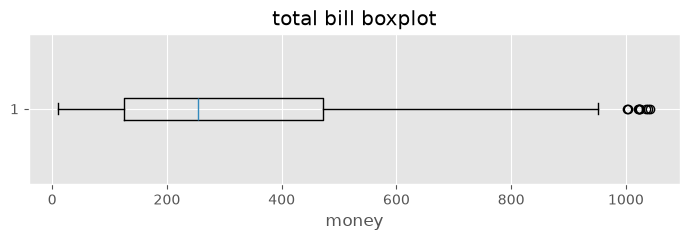

In [11]:
# show the rows that sit above the total upper bound
high_total = supermarket[supermarket["Total"] > 991.74] # this value has been calculated in the previous cell
print("high total rows:", len(high_total))
display(high_total[["Invoice ID", "Branch", "Product line", "Unit price", "Quantity", "Total"]])

# also show boxplot for total
plt.figure(figsize=(7, 2.5))
plt.boxplot(supermarket["Total"], vert=False)
plt.title("total bill boxplot")
plt.xlabel("money")
plt.tight_layout()
plt.show()

outlier method used is iqr with 1.5 times rule.
unit price, quantity, and rating have no outliars.
total, cost, tax, and income have 9 outliars each.
looking at the rows, every one has quantity 10 and a high unit price.
these are real big baskets, not bad rows, so they are kept.

## b3 data cleaning

| problem | how found | decision | justification |
|---|---|---|---|
| date and time as text | dtype check and parse test | convert to datetime types | text cannot be used for time analysis |
| no missing values | missing count cell | keep all rows | nothing to fill, no invented problems |
| no duplicates | duplicate check cell | keep all rows | every invoice is unique |
| constant gross margin | unique value check | keep but do not use as feature | constant column cannot explain anything |
| math linked columns | math check cell | keep and note relation | shows total is defined not measured |
| outliars in total | iqr cell | keep them | they are valid quantity 10 baskets |
| no label issues | whitespace check | no change needed | labels already clean |

derived variables are created because raw date time cannot answer hour, weekday, and month questions.

In [12]:
# start from a copy of raw data
clean = supermarket.copy()

# strip hidden spaces from text columns just to be safe
for col in ["Branch", "City", "Customer type", "Gender", "Product line", "Payment"]:
    clean[col] = clean[col].astype(str).str.strip()

# convert date text into real date values
clean["Date"] = pd.to_datetime(clean["Date"], format="%m/%d/%Y")

# convert time text into real time values
clean["Time"] = pd.to_datetime(clean["Time"], format="%H:%M")

# hour of day from time 10 to 20
clean["hour"] = clean["Time"].dt.hour

# weekday number monday equals 0
clean["weekday_num"] = clean["Date"].dt.weekday

# weekday name like saturday
clean["weekday_name"] = clean["Date"].dt.day_name()

# month number 1 2 3
clean["month_num"] = clean["Date"].dt.month

# month name like january
clean["month_name"] = clean["Date"].dt.month_name()

# weekend flag saturday and sunday equal 1
clean["is_weekend"] = (clean["weekday_num"] >= 5).astype(int)

# money before tax from total minus tax
clean["net_sales"] = clean["Total"] - clean["Tax 5%"]

# show that new columns exist
print("cleaned shape:", clean.shape)
display(clean.head())

cleaned shape: (1000, 24)


,Invoice ID,Branch,City,Customer type,Gender,Product line,Unit price,Quantity,Tax 5%,Total,...,Gross margin percentage,Gross income,Customer stratification rating,hour,weekday_num,weekday_name,month_num,month_name,is_weekend,net_sales
0,750-67-8428,A,Yangon,Member,Female,Health and beauty,74.69,7,26.1415,548.9715,...,4.761905,26.1415,9.1,13,5,Saturday,1,January,1,522.83
1,226-31-3081,C,Naypyitaw,Normal,Female,Electronic accessories,15.28,5,3.8200,80.2200,...,4.761905,3.8200,9.6,10,4,Friday,3,March,0,76.40
2,631-41-3108,A,Yangon,Normal,Male,Home and lifestyle,46.33,7,16.2155,340.5255,...,4.761905,16.2155,7.4,13,6,Sunday,3,March,1,324.31
3,123-19-1176,A,Yangon,Member,Male,Health and beauty,58.22,8,23.2880,489.0480,...,4.761905,23.2880,8.4,20,6,Sunday,1,January,1,465.76
4,373-73-7910,A,Yangon,Normal,Male,Sports and travel,86.31,7,30.2085,634.3785,...,4.761905,30.2085,5.3,10,4,Friday,2,February,0,604.17


In [13]:
# save cleaned file using both name styles
clean_path = "23L_0771_A2_supermarket_cleaned.csv"
clean.to_csv(clean_path, index=False)
print("saved:", clean_path)

saved: 23L_0771_A2_supermarket_cleaned.csv


why each derived column helps.

hour shows when sales happen.
weekday_name shows day of week patterns.
month_name shows month patterns.
is_weekend splits workdays from rest days.
net_sales separates shop revenue from tax component.

## b4 univariate eda

charts chosen by variable type: histograms for spread of numbers, boxplots for outliars, and bar charts for categories.

unit price stats:
count    1000.00
mean       55.67
std        26.49
min        10.08
25%        32.88
50%        55.23
75%        77.94
max        99.96
Name: Unit price, dtype: float64
skew: 0.01


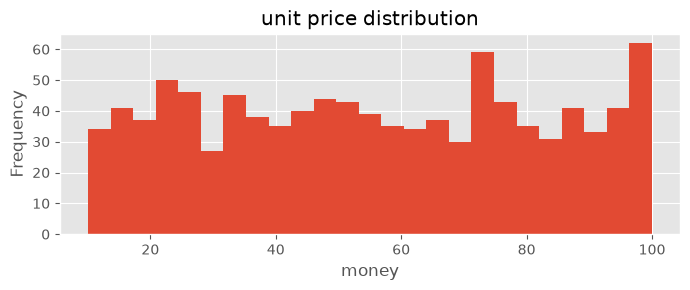

In [14]:
# unit price spread stats
unit = supermarket["Unit price"]
print("unit price stats:")
print(unit.describe().round(2))
print("skew:", round(unit.skew(), 2))

# histogram
unit.plot(kind="hist", bins=25, figsize=(7, 3), title="unit price distribution")
plt.xlabel("money")
plt.tight_layout()
plt.show()

quantity stats:
count    1000.00
mean        5.51
std         2.92
min         1.00
25%         3.00
50%         5.00
75%         8.00
max        10.00
Name: Quantity, dtype: float64


skew: 0.01


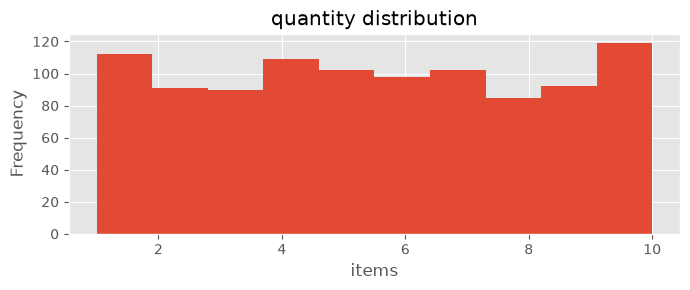


count per quantity value:
Quantity
1     112
2      91
3      90
4     109
5     102
6      98
7     102
8      85
9      92
10    119
Name: count, dtype: int64


In [15]:
# quantity spread stats
qty = supermarket["Quantity"]
print("quantity stats:")
print(qty.describe().round(2))
print("skew:", round(qty.skew(), 2))

# histogram
qty.plot(kind="hist", bins=10, figsize=(7, 3), title="quantity distribution")
plt.xlabel("items")
plt.tight_layout()
plt.show()

# value counts of each quantity
print("\ncount per quantity value:")
print(qty.value_counts().sort_index())

total stats:
count    1000.00
mean      322.97
std       245.89
min        10.68
25%       124.42
50%       253.85
75%       471.35
max      1042.65
Name: Total, dtype: float64
skew: 0.89


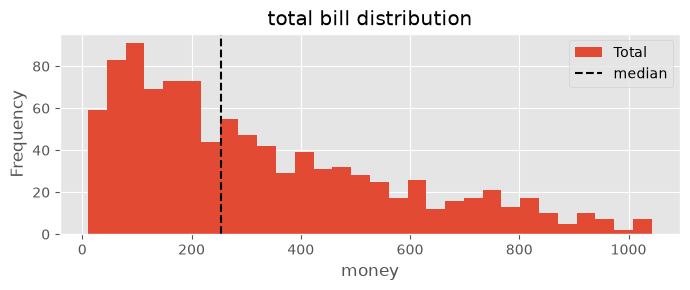

In [16]:
# total bill spread stats
total = supermarket["Total"]
print("total stats:")
print(total.describe().round(2))
print("skew:", round(total.skew(), 2))

# histogram with median line
total.plot(kind="hist", bins=30, figsize=(7, 3), title="total bill distribution")
plt.axvline(total.median(), color="black", linestyle="--", label="median")
plt.xlabel("money")
plt.legend()
plt.tight_layout()
plt.show()

rating stats:
count    1000.00
mean        6.97
std         1.72
min         4.00
25%         5.50
50%         7.00
75%         8.50
max        10.00
Name: Customer stratification rating, dtype: float64


skew: 0.01


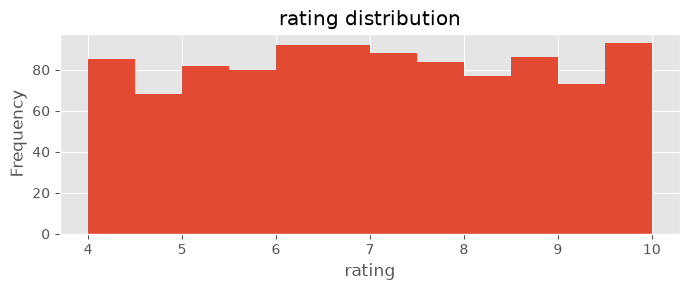

In [17]:
# rating spread stats
rating = supermarket["Customer stratification rating"]
print("rating stats:")
print(rating.describe().round(2))
print("skew:", round(rating.skew(), 2))

# histogram
rating.plot(kind="hist", bins=12, figsize=(7, 3), title="rating distribution")
plt.xlabel("rating")
plt.tight_layout()
plt.show()

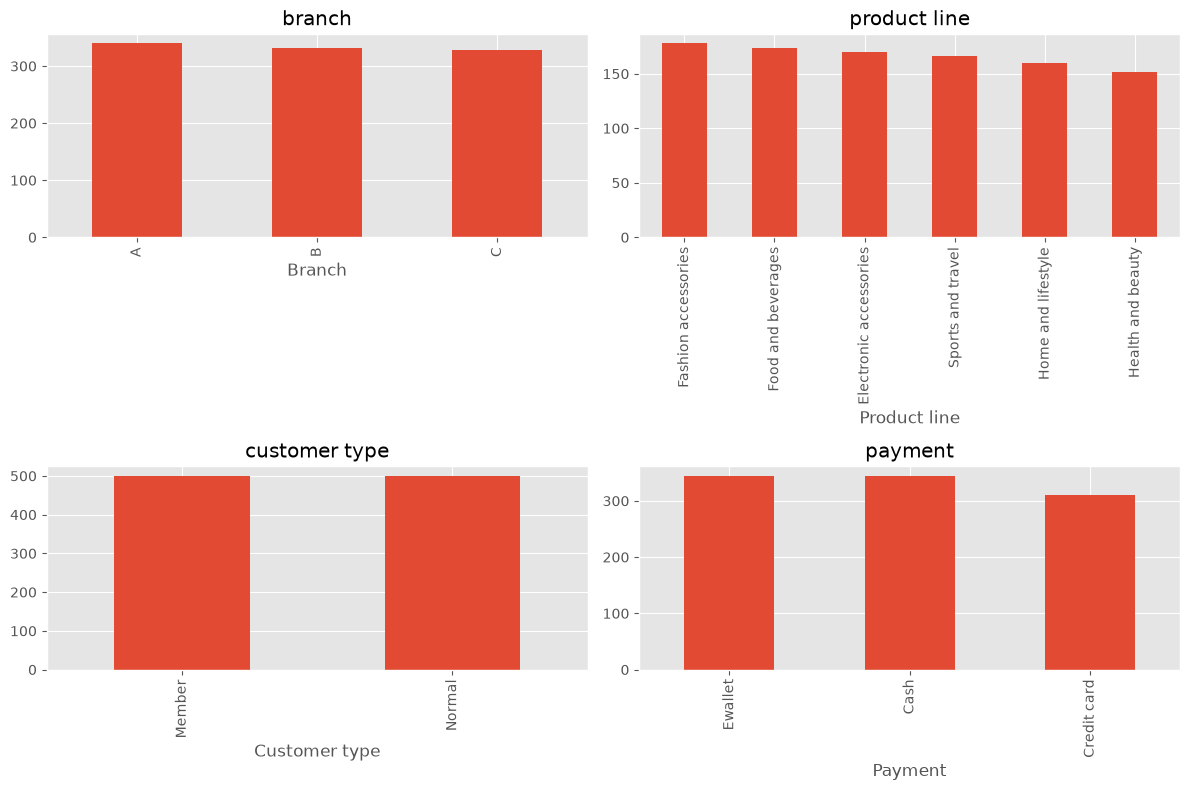

branch counts:
Branch
A    340
B    332
C    328
Name: count, dtype: int64

product line counts:
Product line
Fashion accessories       178
Food and beverages        174
Electronic accessories    170
Sports and travel         166
Home and lifestyle        160
Health and beauty         152
Name: count, dtype: int64

customer type counts:
Customer type
Member    501
Normal    499
Name: count, dtype: int64

payment counts:
Payment
Ewallet        345
Cash           344
Credit card    311
Name: count, dtype: int64


In [18]:
# counts of main categories
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
supermarket["Branch"].value_counts().plot(kind="bar", ax=axes[0, 0], title="branch")
supermarket["Product line"].value_counts().plot(kind="bar", ax=axes[0, 1], title="product line")
supermarket["Customer type"].value_counts().plot(kind="bar", ax=axes[1, 0], title="customer type")
supermarket["Payment"].value_counts().plot(kind="bar", ax=axes[1, 1], title="payment")
plt.tight_layout()
plt.show()

# printed counts as evidence
print("branch counts:")
print(supermarket["Branch"].value_counts())
print("\nproduct line counts:")
print(supermarket["Product line"].value_counts())
print("\ncustomer type counts:")
print(supermarket["Customer type"].value_counts())
print("\npayment counts:")
print(supermarket["Payment"].value_counts())

quick read of the univariate results.

unit price is nearly flat with mean 55.67 and no skew.
quantity centres on 5 items with even spread from 1 to 10.
total is right skewed, mean 322.97 above median 253.85.
rating is almost symmetric, mean 6.97 and median 7.
branch, product line, and payment counts are close to balanced.

## b5 bivariate eda

pairs cover numerical-numerical, numerical-categorical, and categorical-categorical.

In [19]:
# correlation between the number columns
num_cols = ["Unit price", "Quantity", "Tax 5%", "Total", "Cost of goods sold", "Gross income", "Customer stratification rating"]
print("correlation table:")
print(supermarket[num_cols].corr().round(2))

correlation table:
                                Unit price  Quantity  Tax 5%  Total  \
Unit price                            1.00      0.01    0.63   0.63   
Quantity                              0.01      1.00    0.71   0.71   
Tax 5%                                0.63      0.71    1.00   1.00   
Total                                 0.63      0.71    1.00   1.00   
Cost of goods sold                    0.63      0.71    1.00   1.00   
Gross income                          0.63      0.71    1.00   1.00   
Customer stratification rating       -0.01     -0.02   -0.04  -0.04   

                                Cost of goods sold  Gross income  \
Unit price                                    0.63          0.63   
Quantity                                      0.71          0.71   
Tax 5%                                        1.00          1.00   
Total                                         1.00          1.00   
Cost of goods sold                            1.00          1.00   
Gros

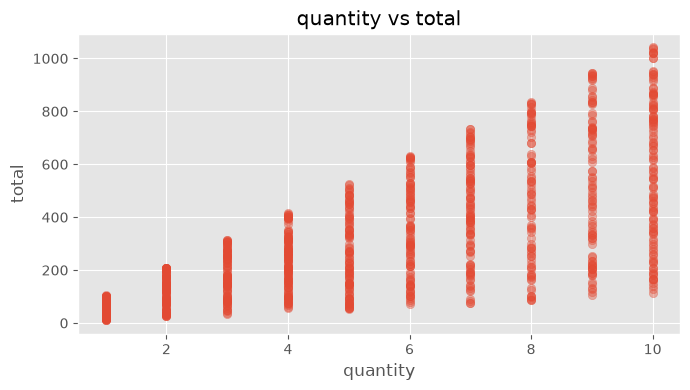

corr quantity total: 0.71


In [20]:
# numerical numerical pair quantity vs total
plt.figure(figsize=(7, 4))
plt.scatter(supermarket["Quantity"], supermarket["Total"], alpha=0.4)
plt.title("quantity vs total")
plt.xlabel("quantity")
plt.ylabel("total")
plt.tight_layout()
plt.show()

print("corr quantity total:", round(supermarket["Quantity"].corr(supermarket["Total"]), 2))

strong positive link between quantity and total.
but remember this is partly an artifact: total is built from quantity and unit price.
so the chart confirms the formula more than a discovered pattern.

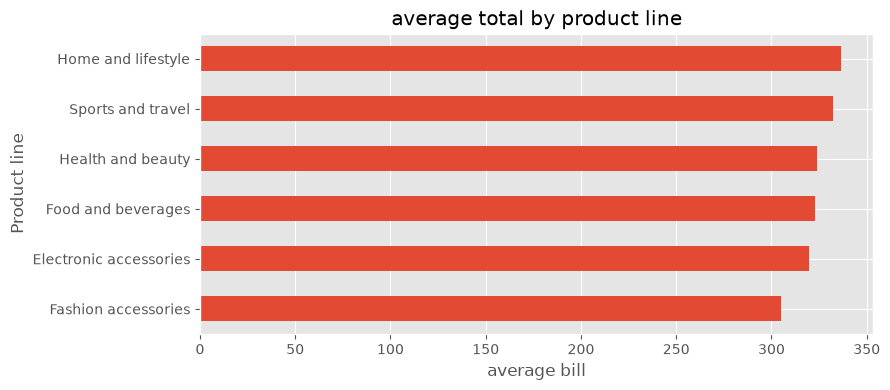

mean total per product line:
Product line
Fashion accessories       305.09
Electronic accessories    319.63
Food and beverages        322.67
Health and beauty         323.64
Sports and travel         332.07
Home and lifestyle        336.64
Name: Total, dtype: float64


In [21]:
# numerical categorical pair product line vs total
plt.figure(figsize=(9, 4))
means = supermarket.groupby("Product line")["Total"].mean().sort_values()
means.plot(kind="barh", figsize=(9, 4), title="average total by product line")
plt.xlabel("average bill")
plt.tight_layout()
plt.show()

print("mean total per product line:")
print(means.round(2))

In [22]:
# categorical categorical pair branch vs city
print("branch vs city:")
print(pd.crosstab(supermarket["Branch"], supermarket["City"], normalize="all").round(2))

# second categorical pair customer type vs payment
print("\ncustomer type vs payment:")
print(pd.crosstab(supermarket["Customer type"], supermarket["Payment"]))

branch vs city:
City    Mandalay  Naypyitaw  Yangon
Branch                             
A           0.00       0.00    0.34
B           0.33       0.00    0.00
C           0.00       0.33    0.00

customer type vs payment:
Payment        Cash  Credit card  Ewallet
Customer type                            
Member          168          172      161
Normal          176          139      184


branch vs city is a perfect one to one map, so it is an artifact of data design.
customer type vs payment shows members and normal customers use all payment methods similarly.

## b6 multivariate eda

here a third variable changes or strengthens a pattern.

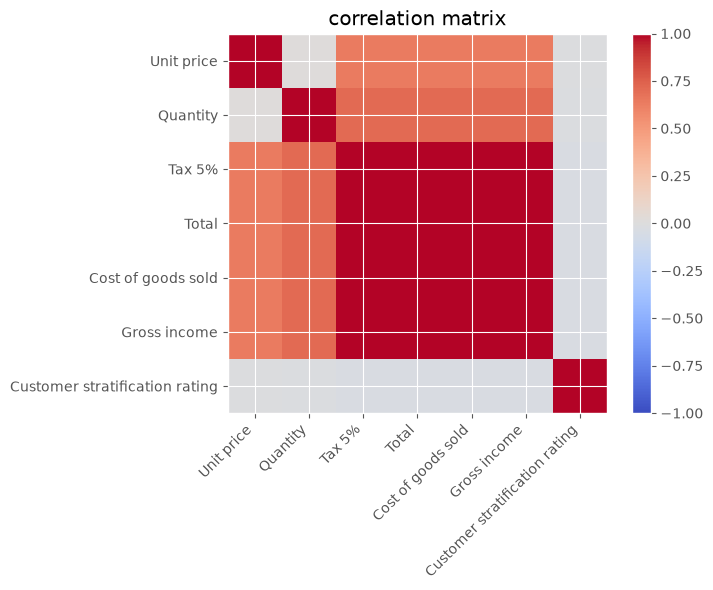

                                Unit price  Quantity  Tax 5%  Total  \
Unit price                            1.00      0.01    0.63   0.63   
Quantity                              0.01      1.00    0.71   0.71   
Tax 5%                                0.63      0.71    1.00   1.00   
Total                                 0.63      0.71    1.00   1.00   
Cost of goods sold                    0.63      0.71    1.00   1.00   
Gross income                          0.63      0.71    1.00   1.00   
Customer stratification rating       -0.01     -0.02   -0.04  -0.04   

                                Cost of goods sold  Gross income  \
Unit price                                    0.63          0.63   
Quantity                                      0.71          0.71   
Tax 5%                                        1.00          1.00   
Total                                         1.00          1.00   
Cost of goods sold                            1.00          1.00   
Gross income           

In [23]:
# correlation matrix picture
fig, ax = plt.subplots(figsize=(8, 6))
corr = supermarket[num_cols].corr()
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(num_cols)))
ax.set_xticklabels(num_cols, rotation=45, ha="right")
ax.set_yticks(range(len(num_cols)))
ax.set_yticklabels(num_cols)
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
ax.set_title("correlation matrix")
plt.tight_layout()
plt.show()

# printed values too
print(corr.round(2))

the matrix shows tax, cost, gross income, and total are almost the same number.
adding customer rating to the picture changes nothing: rating stays near zero with all money columns.

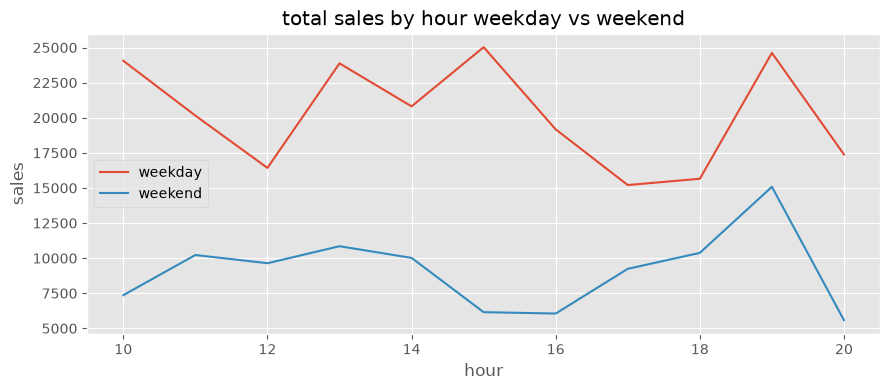

In [24]:
# sales by hour split by weekday vs weekend
clean["hour"] = clean["Time"].dt.hour

# group sums by hour and weekend flag
hour_group = clean.groupby(["hour", "is_weekend"])["Total"].sum().reset_index()
hour_pivot = hour_group.pivot(index="hour", columns="is_weekend", values="Total")

# plot two lines
hour_pivot.plot(figsize=(9, 4), title="total sales by hour weekday vs weekend")
plt.xlabel("hour")
plt.ylabel("sales")
plt.legend(["weekday", "weekend"])
plt.tight_layout()
plt.show()

weekday line runs above weekend line because weekdays have more trading days.
the shape of both lines stays similar, so hour effect holds after adding day type.

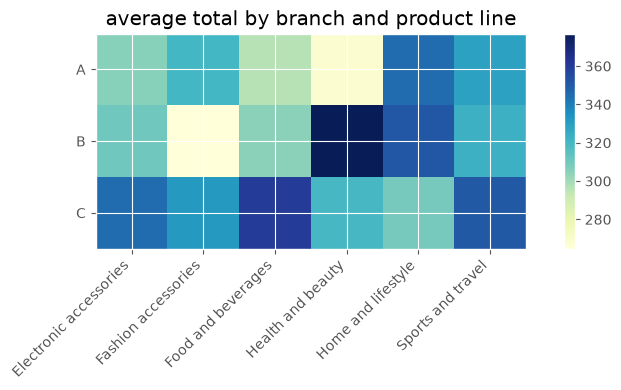

Product line  Electronic accessories  Fashion accessories  Food and beverages  \
Branch                                                                          
A                              305.0                320.0               296.0   
B                              310.0                265.0               304.0   
C                              345.0                332.0               360.0   

Product line  Health and beauty  Home and lifestyle  Sports and travel  
Branch                                                                  
A                         268.0               345.0              328.0  
B                         377.0               351.0              322.0  
C                         320.0               309.0              350.0  


In [25]:
# average total by branch and product line
bp = clean.groupby(["Branch", "Product line"])["Total"].mean().reset_index()
bp_pivot = bp.pivot(index="Branch", columns="Product line", values="Total")

# heat style picture
fig, ax = plt.subplots(figsize=(10, 4))
im = ax.imshow(bp_pivot, cmap="YlGnBu")
ax.set_xticks(range(len(bp_pivot.columns)))
ax.set_xticklabels(bp_pivot.columns, rotation=45, ha="right")
ax.set_yticks(range(len(bp_pivot.index)))
ax.set_yticklabels(bp_pivot.index)
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
ax.set_title("average total by branch and product line")
plt.tight_layout()
plt.show()

# printed table
print(bp_pivot.round(0))

branch and product line together show only small differences.
no cell stands far out, so branch alone does not drive a strong pattern.

## b7 supermarket sales specific analytical questions

question 1 which product lines contribute most to revenue, and does ranking change with average transaction value

,revenue,rev_rank,avg_txn,avg_rank
Product line,,,,
Food and beverages,56145.0,1.0,322.67,4.0
Sports and travel,55123.0,2.0,332.07,2.0
Electronic accessories,54338.0,3.0,319.63,5.0
Fashion accessories,54306.0,4.0,305.09,6.0
Home and lifestyle,53862.0,5.0,336.64,1.0
Health and beauty,49194.0,6.0,323.64,3.0


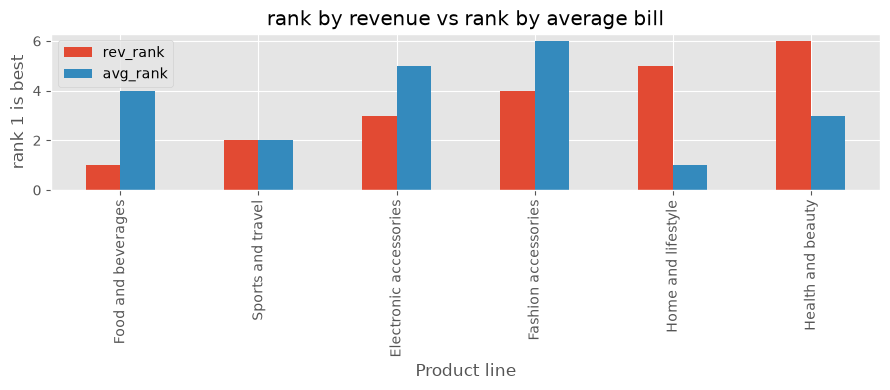

In [26]:
# revenue by product line sum of totals
revenue = supermarket.groupby("Product line")["Total"].sum().sort_values(ascending=False)

# average transaction value by product line mean of totals
avg_txn = supermarket.groupby("Product line")["Total"].mean().sort_values(ascending=False)

# side by side with ranks best rank is 1
q1 = pd.DataFrame({
    "revenue": revenue.round(0),
    "rev_rank": revenue.rank(ascending=False),
    "avg_txn": avg_txn.round(2),
    "avg_rank": avg_txn.rank(ascending=False)
})
display(q1.sort_values("rev_rank"))

# chart both
q1[["rev_rank", "avg_rank"]].sort_values("rev_rank").plot(kind="bar", figsize=(9, 4), title="rank by revenue vs rank by average bill")
plt.ylabel("rank 1 is best")
plt.tight_layout()
plt.show()

answer
food and beverages lead revenue with about 56145, and health and beauty is last with about 49194.
ranking does change when average transaction value is used.
home and lifestyle jumps to first place with average bill 336.64.
fashion accessories falls to last place with 305.09 even though it is mid in revenue.
this happens because revenue mixes price, quantity, and count of receipts.

question 2 do branches or cities differ in sales, quantities, or ratings compared with variation inside each branch

,receipts,total_sum,total_mean,total_std,qty_mean,rating_mean,rating_std
Branch,,,,,,,
A,340,106200.37,312.35,231.64,5.47,7.03,1.73
B,332,106197.67,319.87,242.45,5.48,6.82,1.71
C,328,110568.71,337.10,263.16,5.58,7.07,1.70


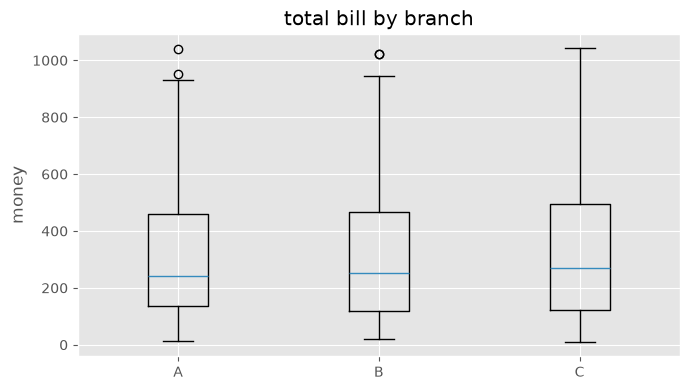

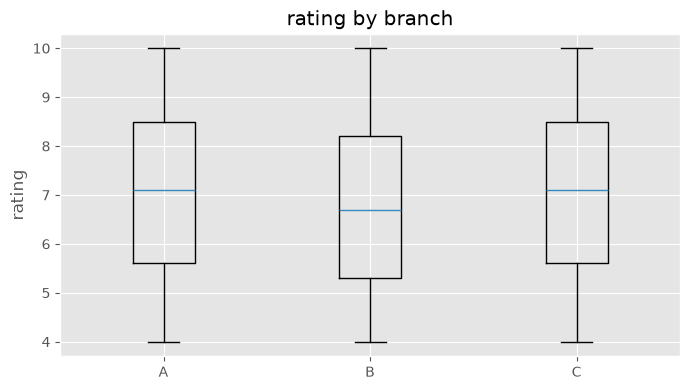

In [27]:
# branch level summary
branch_stats = supermarket.groupby("Branch").agg(
    receipts=("Invoice ID", "count"),
    total_sum=("Total", "sum"),
    total_mean=("Total", "mean"),
    total_std=("Total", "std"),
    qty_mean=("Quantity", "mean"),
    rating_mean=("Customer stratification rating", "mean"),
    rating_std=("Customer stratification rating", "std")
)
display(branch_stats.round(2))

# boxplot of totals by branch
groups = [supermarket[supermarket["Branch"] == b]["Total"] for b in ["A", "B", "C"]]
plt.figure(figsize=(7, 4))
plt.boxplot(groups, tick_labels=["A", "B", "C"])
plt.title("total bill by branch")
plt.ylabel("money")
plt.tight_layout()
plt.show()

# boxplot of rating by branch
groups_r = [supermarket[supermarket["Branch"] == b]["Customer stratification rating"] for b in ["A", "B", "C"]]
plt.figure(figsize=(7, 4))
plt.boxplot(groups_r, tick_labels=["A", "B", "C"])
plt.title("rating by branch")
plt.ylabel("rating")
plt.tight_layout()
plt.show()

answer
branch c has the highest average bill around 337, against a 312 and b 320.
quantity per receipt is nearly identical, about 5.5 for all three.
ratings are close too, 7.03, 6.82, and 7.07, with standard deviation near 1.7 inside each branch.
the inside variation is much bigger than the gap between branch means.
so branch differences exist, but they are small in practice.

question 3 do member normal customers, or payment methods, differ in spending behaviour

average bill by customer type:
Customer type
Member    327.79
Normal    318.12
Name: Total, dtype: float64

average bill by payment method:
Payment
Cash           326.18
Credit card    324.01
Ewallet        318.82
Name: Total, dtype: float64

receipts by customer type:
Customer type
Member    501
Normal    499
Name: count, dtype: int64

receipts by payment:
Payment
Ewallet        345
Cash           344
Credit card    311
Name: count, dtype: int64


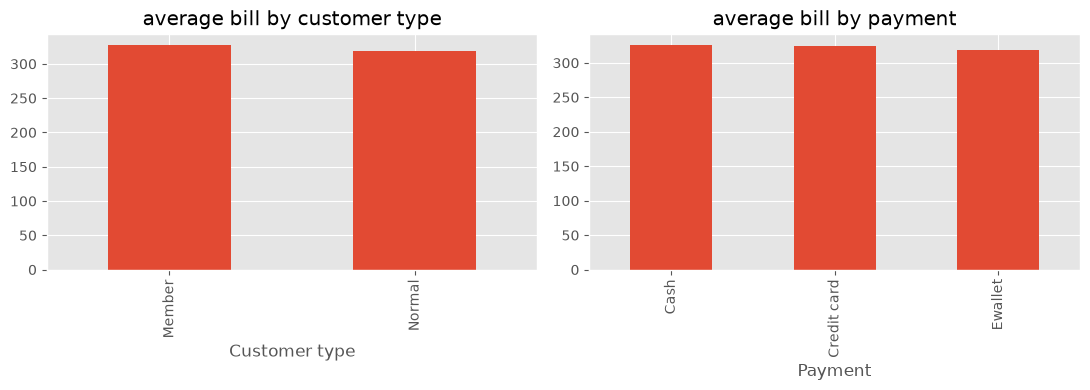

In [28]:
# average bill by customer type
print("average bill by customer type:")
print(supermarket.groupby("Customer type")["Total"].mean().round(2))

# average bill by payment method
print("\naverage bill by payment method:")
print(supermarket.groupby("Payment")["Total"].mean().round(2))

# receipts count too
print("\nreceipts by customer type:")
print(supermarket["Customer type"].value_counts())
print("\nreceipts by payment:")
print(supermarket["Payment"].value_counts())

# simple bars
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
supermarket.groupby("Customer type")["Total"].mean().plot(kind="bar", ax=axes[0], title="average bill by customer type")
supermarket.groupby("Payment")["Total"].mean().plot(kind="bar", ax=axes[1], title="average bill by payment")
plt.tight_layout()
plt.show()

answer
members average about 327.79 and normal customers about 318.12, so member spend is only slightly higher.
cash receipts average 326.18, credit card 324.01, and ewallet 318.82, so gaps are tiny.
with this small distance and spread of totals around 245, the differences look weak.

question 4 how do sales vary by time of day, and by day of week

sales by hour:
hour
10    31421.0
11    30377.0
12    26066.0
13    34723.0
14    30828.0
15    31180.0
16    25226.0
17    24445.0
18    26030.0
19    39700.0
20    22970.0
Name: Total, dtype: float64


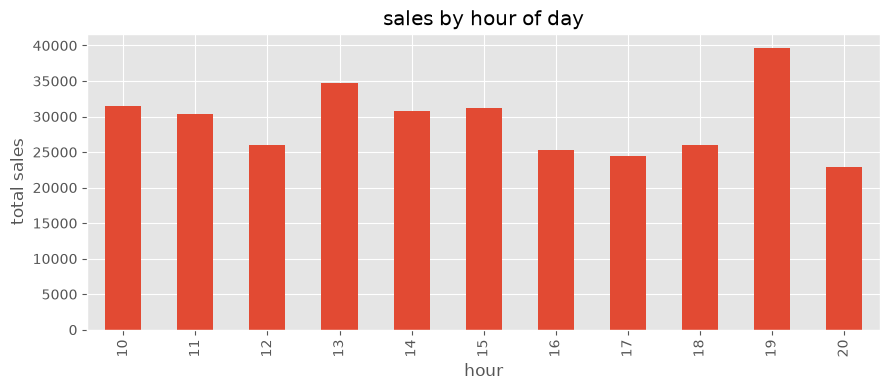


sales by weekday:
weekday_name
Monday       37899.0
Tuesday      51482.0
Wednesday    43731.0
Thursday     45349.0
Friday       43926.0
Saturday     56121.0
Sunday       44458.0
Name: Total, dtype: float64


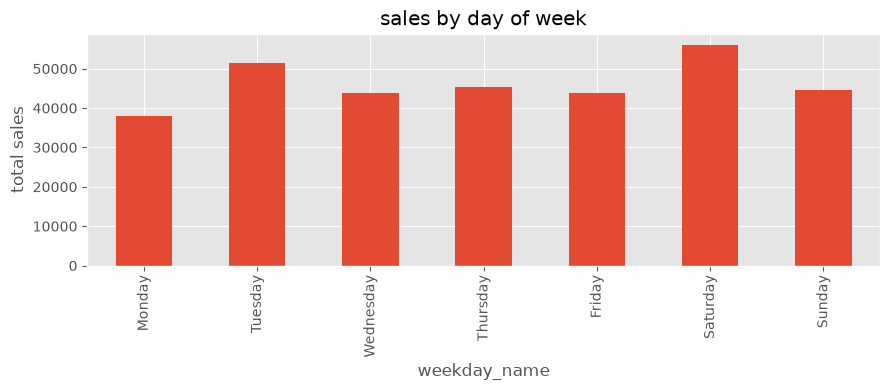

In [29]:
# sales by hour
by_hour = clean.groupby("hour")["Total"].sum()
print("sales by hour:")
print(by_hour.round(0))

by_hour.plot(kind="bar", figsize=(9, 4), title="sales by hour of day")
plt.ylabel("total sales")
plt.tight_layout()
plt.show()

# sales by weekday with proper order
order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
by_day = clean.groupby("weekday_name")["Total"].sum().reindex(order)
print("\nsales by weekday:")
print(by_day.round(0))

by_day.plot(kind="bar", figsize=(9, 4), title="sales by day of week")
plt.ylabel("total sales")
plt.tight_layout()
plt.show()

answer
biggest hours are 19 with about 39700 and 13 with about 34723.
quietest hours are 17 and 20.
saturday leads the week with about 56121, and monday is lowest with about 37899.
speculation label: the data cannot explain why people shop more at these times.

question 5 is customer rating related to price, quantity, product line, or branch

correlation of rating with other columns:
unit price: -0.009


quantity: -0.016
total: -0.036

rating mean by product line:
Product line
Food and beverages        7.11
Fashion accessories       7.03
Health and beauty         7.00
Electronic accessories    6.92
Sports and travel         6.92
Home and lifestyle        6.84
Name: Customer stratification rating, dtype: float64

rating mean by branch:
Branch
A    7.03
B    6.82
C    7.07
Name: Customer stratification rating, dtype: float64


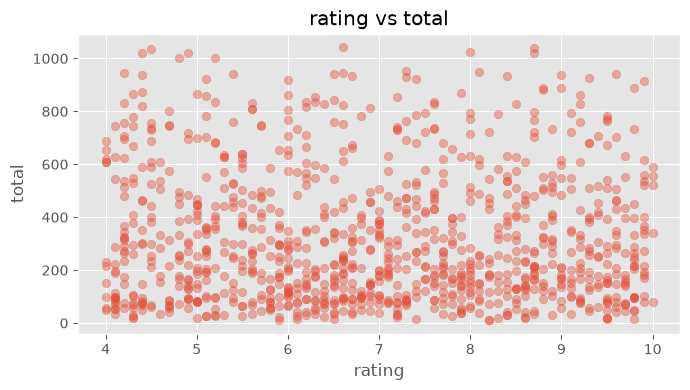

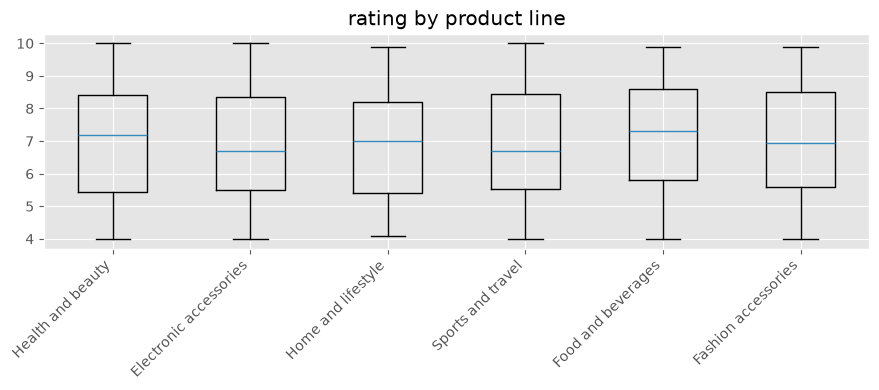

In [30]:
# rating against money numbers
print("correlation of rating with other columns:")
print("unit price:", round(supermarket["Customer stratification rating"].corr(supermarket["Unit price"]), 3))
print("quantity:", round(supermarket["Customer stratification rating"].corr(supermarket["Quantity"]), 3))
print("total:", round(supermarket["Customer stratification rating"].corr(supermarket["Total"]), 3))

# rating mean by product line
print("\nrating mean by product line:")
print(supermarket.groupby("Product line")["Customer stratification rating"].mean().round(2).sort_values(ascending=False))

# rating mean by branch
print("\nrating mean by branch:")
print(supermarket.groupby("Branch")["Customer stratification rating"].mean().round(2))

# scatter rating vs total
plt.figure(figsize=(7, 4))
plt.scatter(supermarket["Customer stratification rating"], supermarket["Total"], alpha=0.4)
plt.title("rating vs total")
plt.xlabel("rating")
plt.ylabel("total")
plt.tight_layout()
plt.show()

# rating boxplot by product line
groups = [supermarket[supermarket["Product line"] == p]["Customer stratification rating"] for p in supermarket["Product line"].unique()]
plt.figure(figsize=(9, 4))
plt.boxplot(groups, tick_labels=supermarket["Product line"].unique())
plt.title("rating by product line")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

answer
correlations of rating with unit price, quantity, and total are all near zero around -0.01 to -0.04.
rating means by product line sit between 6.84 and 7.11, which is a tiny range.
branch means are 7.03, 6.82, and 7.07, also close.
so rating looks unconnected to price, quantity, and basket size.
what it suggests is that rating captures something else, like service feeling.
the data cannot confirm the cause.

## b8 insights and handoff

five meaningful insights.

1 revenue by product line is tight: top food and beverages about 56145 and bottom health and beauty about 49194, a gap near 14 percent, so no line dominates.

2 branch c average bill 337.10 vs branch a 312.35 and branch b 319.87, but within branch total standard deviation is about 245, so the branch gap is small next to inside spread.

3 member average bill 327.79 vs normal 318.12, and cash 326.18 vs ewallet 318.82, both differences under 3 percent. interpretation: weak effect. speculation label: the data cannot tell if membership causes higher spend.

4 peak hour 19 reaches about 39700 sales and saturday about 56121 against monday 37899. interpretation: traffic varies by time. speculation label: reason unknown from this data.

5 rating shows near zero correlation with total -0.036, unit price -0.009, and quantity -0.016. interpretation: rating seems independent of basket size and price.

handoff note for assignment 3

informative variables are Total, Quantity, Unit price, Product line, hour, and weekday_name.
branch and city are the same info, keep one of them.
Cost of goods sold, Tax 5%, and Gross income are recomputed from Unit price and Quantity, so avoid using all money columns together with Total.
Gross margin percentage is constant and should be dropped as a feature.
Date and Time text should not be features raw; use the derived hour, weekday, and month columns instead.
Invoice ID is an identifier only.
outliers in Total were kept because they are valid quantity 10 receipts.
no missing values or duplicates were found, so nothing was filled or removed.